# Milestone 2: Initial Exploratory Data Analysis (EDA)
**Objective:** Connect to the PostgreSQL database, build customer-level aggregates, and evaluate the underlying shape of our customer base and spending habits.

In [2]:
import ssl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pg8000

# Setup secure connection to Neon PostgreSQL database
ssl_context = ssl.create_default_context()
ssl_context.check_hostname = False
ssl_context.verify_mode = ssl.CERT_NONE

conn = pg8000.connect(
    user="ecom_ro_user",
    password="work-experience-read-only",
    host="ep-bold-hall-azhf2f45-pooler.c-3.ap-southeast-1.aws.neon.tech",
    database="neondb",
    port=5432,
    ssl_context=ssl_context
)
print("Connection established successfully.")

Connection established successfully.


### 1. Building Customer-Level Aggregates
We aggregate order-level records down to one row per customer to evaluate lifetime metrics: total spend, order count, first order date, and last order date.

In [3]:
query = """
SELECT 
    customer_id,
    COUNT(order_id) AS order_count,
    SUM(total) AS total_spend,
    MIN(created_at) AS first_order_date,
    MAX(created_at) AS last_order_date
FROM ecom.orders
GROUP BY customer_id;
"""

df_customers = pd.read_sql(query, con=conn)

print(f"Total Unique Customers: {df_customers['customer_id'].nunique():,}")
print(f"Date Range: {df_customers['first_order_date'].min()} to {df_customers['last_order_date'].max()}")
df_customers.head()

Total Unique Customers: 8,800
Date Range: 2026-03-16 00:13:57+00:00 to 2026-06-14 23:28:40+00:00


,customer_id,order_count,total_spend,first_order_date,last_order_date
0,6114,1,4835.64,2026-05-30 05:16:02+00:00,2026-05-30 05:16:02+00:00
1,4790,2,14033.74,2026-04-02 18:10:41+00:00,2026-04-02 21:33:39+00:00
2,273,1,3065.64,2026-05-03 14:03:03+00:00,2026-05-03 14:03:03+00:00
3,3936,5,41818.02,2026-03-22 09:22:37+00:00,2026-04-04 15:04:06+00:00
4,5761,6,51488.12,2026-04-05 06:54:45+00:00,2026-05-02 23:24:39+00:00


### 2. Summary Statistics & Distribution Check
*Note on troubleshooting:* Initial attempts to use `psycopg2` encountered local C-compiler errors (`pg_config` missing), so we shifted cleanly to the pure-Python `pg8000` driver. 

Let's check `df_describe()` to understand central tendencies and skewness.

In [4]:
display(df_customers.describe())

,customer_id,order_count,total_spend
count,8800.000000,8800.000000,8.800000e+03
mean,5022.968409,4.545455,3.394933e+04
std,2884.625415,9.893442,7.797525e+04
min,1.000000,1.000000,1.758200e+02
25%,2529.500000,1.000000,3.773640e+03
50%,5038.500000,1.000000,1.167846e+04
75%,7521.250000,5.000000,3.824318e+04
max,10000.000000,178.000000,1.459762e+06


### 3. Visualizing Spending Distribution
Let's inspect how spending is distributed across the base to see if standard averages hold true or if power buyers skew the dataset.

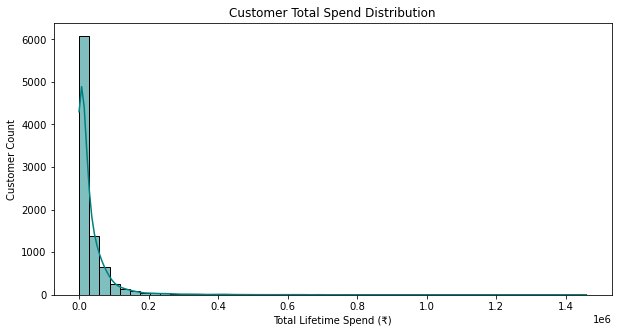

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df_customers['total_spend'], bins=50, kde=True, color='teal')
plt.title('Customer Total Spend Distribution')
plt.xlabel('Total Lifetime Spend (₹)')
plt.ylabel('Customer Count')
plt.show()